# Counting barnacles in NPS frame photos
**DALI Data Challenge 26F · David Shen**

This is the long version: what I tried, in order, and why I changed course each time. The short version (final system, how to run it) is in `README.md`.
Sections 1-9 roughly provide the timeline of different model schemas and tests I ran for differing parameters. Beyond is more housekeeping information.

- **[runs]** = the cell actually computes it, on a CPU, no PyTorch needed (whole notebook takes about a minute).
- **[saved]** = loads results saved by earlier experiments in `results/recorded/`. Those took hours or needed PyTorch. The code for them is in `experiments/`.

In [1]:
# all the real code lives in barnacle_counter/, this notebook just calls it
import json
from pathlib import Path
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import barnacle_counter as bc
from barnacle_counter import marks as mk, plots, baselines, audit


def saved(name):
    # results saved by earlier runs
    return json.loads(Path('results/recorded', name).read_text())


frames = json.loads(Path('data/frames.json').read_text())   # the 4 inner frame corners for each photo
cfg = json.loads(Path('models/default.json').read_text())    # main model + its threshold
print(Path(cfg['model']).name, '| threshold', cfg['threshold'])

Matplotlib is building the font cache; this may take a moment.


mixed_0.5_yolo11n.pt | threshold 0.37


## 1. The problem

Scientists put a fixed green frame on the rock, take a photo, and count every barnacle inside the frame by hand. Often 1,000+ per photo. We get 2 photos with every barnacle outlined (`mask1/2.png`) and 1 photo with no labels (`unseen_img1.png`).

First, straighten the frame. Click the 4 inner corners and warp the inside into a flat 1024×1024 square. The frame is always the same size, so barnacles come out about the same size in pixels on every photo. That turns out to matter a lot. **[runs]**

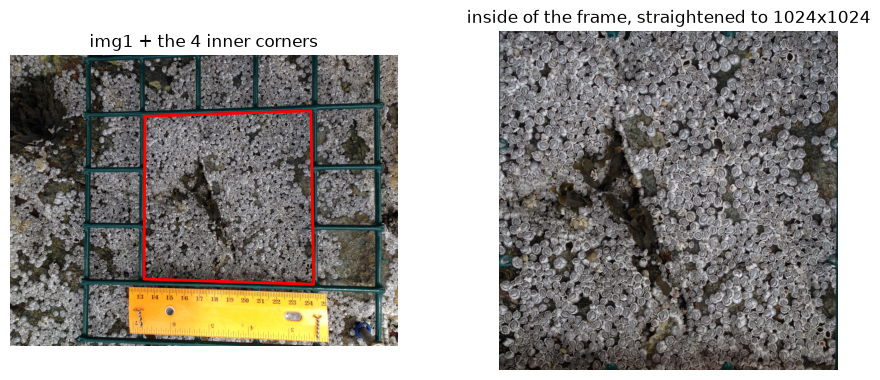

In [2]:
raw = bc.read_rgb('data/img1.png')
rect, _ = bc.rectify(raw, frames['img1.png'])
c = np.array(frames['img1.png'] + [frames['img1.png'][0]])
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ax[0].imshow(raw); ax[0].plot(c[:, 0], c[:, 1], 'r-', lw=2); ax[0].set_title('img1 + the 4 inner corners')
ax[1].imshow(rect); ax[1].set_title('inside of the frame, straightened to 1024x1024')
for a in ax: a.axis('off')
plt.show()

Turn the mask outlines into an answer key: one point per barnacle opening (the masks are just outlines, so each enclosed hole = one barnacle). **[runs]**

photo 1: 1659 barnacles, typical opening radius 6.9 px
photo 2: 395 barnacles, typical opening radius 8.4 px


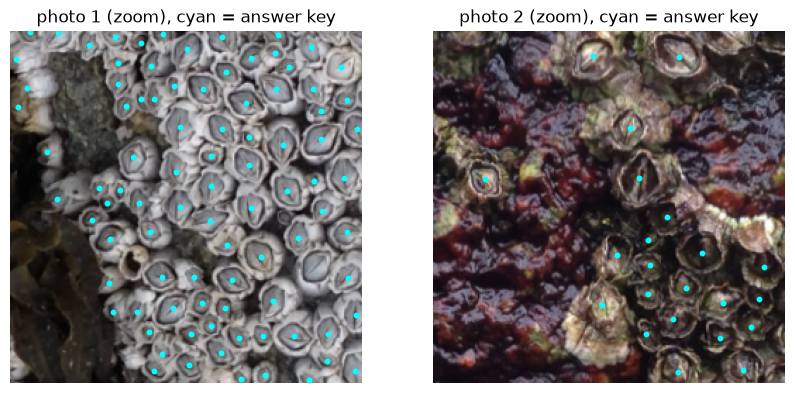

In [3]:
photos = {}
for k in (1, 2):
    rgb, M = bc.rectify(bc.read_rgb(f'data/img{k}.png'), frames[f'img{k}.png'])
    ref = bc.load_reference(f'data/mask{k}.png', M)   # rows: x, y, radius
    photos[k] = dict(rgb=rgb, ref=ref)
    print(f'photo {k}: {len(ref)} barnacles, typical opening radius {np.median(ref[:, 2]):.1f} px')

fig, ax = plt.subplots(1, 2, figsize=(10, 4.6))
for a, k in zip(ax, (1, 2)):
    ref = photos[k]['ref']; box = (400, 400, 650, 650); m = bc.in_box(ref, box)
    a.imshow(photos[k]['rgb'][400:650, 400:650]); a.scatter(ref[m, 0] - 400, ref[m, 1] - 400, s=10, c='cyan')
    a.set_title(f'photo {k} (zoom), cyan = answer key'); a.axis('off')
plt.show()

Quick look at the masks themselves (sizes, spacing). **[saved]**

In [4]:
dx = saved('data_exploration.json')['summary']
for k in (1, 2):
    s = dx[f'dali_photo{k}']
    print(f"photo {k}: {s['n']} openings, median radius {s['radius_p5_25_50_75_95'][2]:.1f} px, median gap to nearest neighbour {s['nn_distance_p5_25_50_75_95'][2]:.1f} px, "
          f"touching a neighbour {100 * s['share_touching_or_overlapping']:.1f}%, size vs crowding correlation {s['radius_vs_local_count_spearman']:.2f}")

photo 1: 1659 openings, median radius 6.9 px, median gap to nearest neighbour 18.4 px, touching a neighbour 1.3%, size vs crowding correlation -0.39
photo 2: 395 openings, median radius 8.4 px, median gap to nearest neighbour 30.4 px, touching a neighbour 0.0%, size vs crowding correlation -0.45


Openings almost never touch, so two dots right next to each other are usually a double count. Crowded barnacles are smaller. Photo 1 is about 4x denser than photo 2.

What counts as a barnacle (my rules):
- inside the inner square of the frame only
- empty shells don't count. Paul (DALI data dev head) pointed out the empty ones aren't outlined in the masks, so I follow the masks.
- one cut by the edge counts only if its centre is inside

## 2. How I score it

A dot is right if it lands on a barnacle (within 0.75 × that barnacle's radius, at least 3 px). One dot per barnacle, a second dot on the same barnacle is an extra.
- **precision** = share of dots that are on a barnacle
- **recall** = share of barnacles that got a dot
- **F1** = both in one number, 1.0 = perfect

Notably F1 is not true count accuracy. It is more punishing. 10 extra dots + 10 missed barnacles gives a perfect total but a worse F1. Thus, this removes the possibility of evaluating a result dependent on luck. So I report the count error separately.

Only 2 labelled photos, so each one gets split by position. **[runs]**

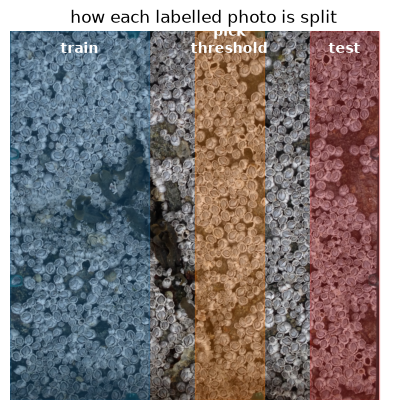

In [5]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(photos[1]['rgb'])
for x0, x1, col, name in [(0, 384, 'tab:blue', 'train'), (512, 704, 'tab:orange', 'pick\nthreshold'), (832, 1024, 'tab:red', 'test')]:
    ax.axvspan(x0, x1, color=col, alpha=.3)
    ax.text((x0 + x1) / 2, 60, name, ha='center', color='white', fontsize=10, weight='bold')
ax.set_title('how each labelled photo is split'); ax.axis('off')
plt.show()

Catch I only figured out later: this tests "did it learn these two photos", not "does it work on a new photo". More on that in section 6.

## 3. Idea 1: describe what a barnacle looks like

My first idea: a barnacle looks like a bright raised ring with a dark slit in the middle. I personally was thinking about recognizing the circles through gradients and using a light gradient to detect a ring and slits. So build filters (convolution kernels) for that pattern and look for it. Quick demo on a patch of photo 2. **[runs]**

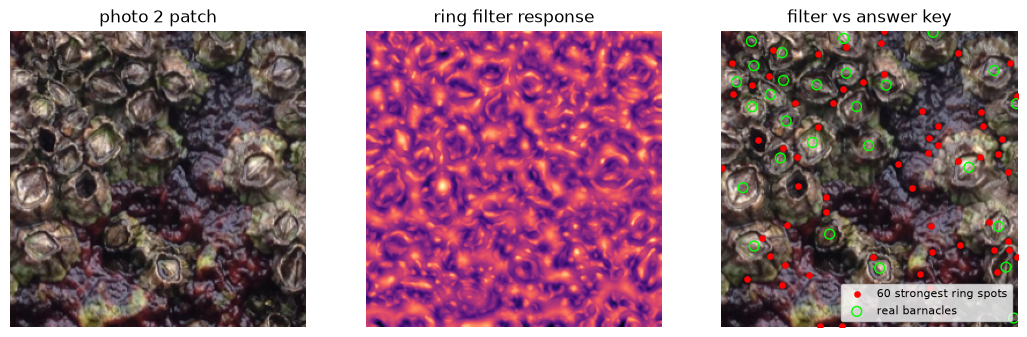

In [6]:
patch = photos[2]['rgb'][300:556, 300:556]
resp = baselines.ring_response(baselines.normalized_gray(patch))   # ring-minus-centre filter at 4 sizes
pk = baselines.peaks(resp, top=60)
ref = photos[2]['ref']; m = bc.in_box(ref, (300, 300, 556, 556))
fig, ax = plt.subplots(1, 3, figsize=(13, 4.4))
ax[0].imshow(patch); ax[0].set_title('photo 2 patch')
ax[1].imshow(resp, cmap='magma'); ax[1].set_title('ring filter response')
ax[2].imshow(patch); ax[2].scatter(pk[:, 0], pk[:, 1], s=14, c='red', label='60 strongest ring spots')
ax[2].scatter(ref[m, 0] - 300, ref[m, 1] - 300, s=50, facecolors='none', edgecolors='lime', label='real barnacles')
ax[2].legend(loc='lower right', fontsize=8); ax[2].set_title('filter vs answer key')
for a in ax: a.axis('off')
plt.show()

Some hits, lots of junk as you can see are very poor as the model misinterprets a lot of the rock formation to be ring structure also my first introduction to the idea of empty barnacle shells being mislabeled. This is where I came up more with a lighting a gradient to detect whether it is empty or has real contents. The real numbers **[saved]**:

In [7]:
r1 = {(r['source_image'], r['method']): r['f1'] for r in saved('round1_filter_metrics.json')['results']}
cv = saved('classical_cv.json')
rr = {r['image']: r['f1'] for r in saved('ring_rule_tests.json')['literal_edge_band'] if r['profile'] == 'literal_edge_band_5pct_line70'}
display(pd.DataFrame([
    # strict ring + slit rule (ring edge within 5% of the radius + dark line across 70% of it), scored on each photo itself
    dict(method='strict ring + slit rule (scored on the same photo)', **{'photo 1': rr[1], 'photo 2': rr[2]}),
    dict(method='ring kernel, train on one photo -> test on the other', **{'photo 1': cv['dali_2to1']['ring']['target']['f1'],
                                                                         'photo 2': cv['dali_1to2']['ring']['target']['f1']}),
    dict(method='ring/slit/gradient filters + tree classifier (train on other photo)',
         **{'photo 1': r1[(2, 'structural_gradient_stability')], 'photo 2': r1[(1, 'structural_gradient_stability')]}),
]).round(3))

,method,photo 1,photo 2
0,strict ring + slit rule (scored on the same ph...,0.000,0.008
1,"ring kernel, train on one photo -> test on the...",0.002,0.058
2,ring/slit/gradient filters + tree classifier (...,0.140,0.091


Basically nothing. Real barnacles break the rule: the inside isn't always dark (brightness drops at the rim, comes back up, then drops again at the seam), lighting and moss change things, they're crowded. And empty shells have perfect rings but don't count. Thus, that provided schema for barnacle detection would fail.

## 4. Idea 2: more detail, let a classifier decide

Instead of one hard rule: measure brightness along lines out from the centre (profiles) plus gradients, and let a classifier weigh them. I hand-edited the code for these gradient tests. **[saved]**

In [8]:
prof = {(r['source'], r['method']): r['f1'] for r in saved('profile_transfer.json')}
display(pd.DataFrame({'features': ['brightness profiles', 'profiles + gradients'],
                      'train photo 1 -> test photo 2': [prof[(1, 'profile')], prof[(1, 'profile_hog')]],
                      'train photo 2 -> test photo 1': [prof[(2, 'profile')], prof[(2, 'profile_hog')]]}).round(3))

,features,train photo 1 -> test photo 2,train photo 2 -> test photo 1
0,brightness profiles,0.041,0.062
1,profiles + gradients,0.238,0.354


Gradients helped (0.04/0.06 → 0.24/0.35) but still bad. And the step before the classifier (finding candidate spots) was already missing barnacles. A classifier can't rescue a barnacle that never got proposed. Tweaking thresholds wasn't going to fix that.

## 5. Idea 3: let a model learn what a barnacle looks like

At this point I kinda threw in the towel for hand rules and I was just focusing more on trying to optimize. So effectively, I said forget the hand rules, find something that actually gives a usable F1. → **YOLO11n**, a small object detector. Two options: train from scratch, or start from weights already trained on COCO (everyday photos) and fine-tune on barnacles. 

Barnacles are tiny, so the frame gets cut into overlapping 256px tiles, each blown up to 512px. Each tile owns a "core" so a barnacle in the overlap isn't counted twice. The idea is that if the center of the barnacle is not within the indicate frame then it will not be counted. Still there is ambiguity with this statement as how can you know if something is the center if you don't have the full object. **[runs]**

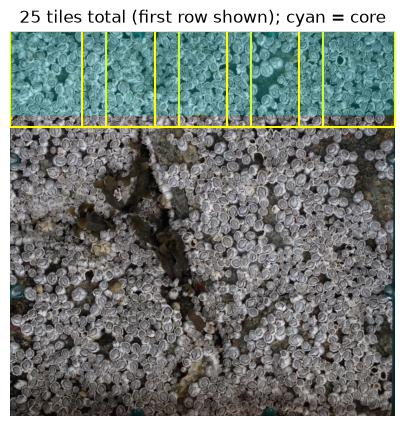

In [9]:
ws = bc.windows()
fig, ax = plt.subplots(figsize=(5, 5)); ax.imshow(photos[1]['rgb'])
for w in ws[:5]:   # first row of tiles
    x0, y0, x1, y1 = w['crop']; ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec='yellow', lw=1.5))
    a0, b0, a1, b1 = w['core']; ax.add_patch(plt.Rectangle((a0, b0), a1 - a0, b1 - b0, fc='cyan', alpha=.2))
ax.set_title(f'{len(ws)} tiles total (first row shown); cyan = core'); ax.axis('off')
plt.show()

**The main model:** COCO-pretrained YOLO11n, fine-tuned on a random half of the tiles from the left strip of both photos. Settings straight from the training run's `args.yaml`, and the training curve from `results.csv`. **[runs]**

The 4 sleeker strips in between each larger tile act as buffer zones so that there would not be overlap of data. In the context of this challenge, that would be a barnacle counting in both images because it is cut in half for both one and the other. While it does remove information, I believe that this buffer-zone process is necessary in order to avoid any biases and overcounting.

{'model': 'yolo11n.pt', 'epochs': 100, 'imgsz': 512, 'batch': 8, 'optimizer': 'AdamW', 'lr0': 0.001, 'degrees': 180, 'fliplr': 0.5, 'flipud': 0.5, 'mosaic': 0.3, 'seed': 42}


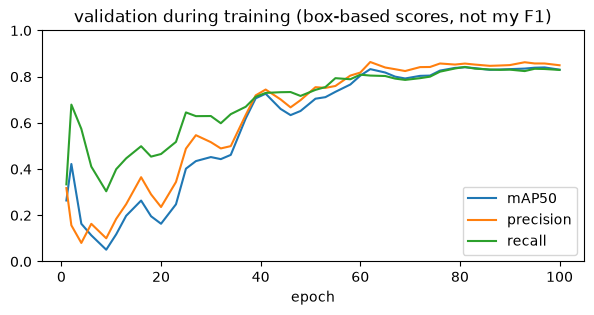

In [10]:
args = yaml.safe_load(Path('models/args.yaml').read_text())
print({k: args[k] for k in ['model', 'epochs', 'imgsz', 'batch', 'optimizer', 'lr0', 'degrees', 'fliplr', 'flipud', 'mosaic', 'seed']})
log = pd.read_csv('models/results.csv')
log = log[log['metrics/mAP50(B)'].diff().fillna(1) != 0]   # validation only re-ran every 2-3 epochs, drop repeats
fig, ax = plt.subplots(figsize=(7, 3))
for col, name in [('metrics/mAP50(B)', 'mAP50'), ('metrics/precision(B)', 'precision'), ('metrics/recall(B)', 'recall')]:
    ax.plot(log['epoch'], log[col], label=name)
ax.set_xlabel('epoch'); ax.set_ylim(0, 1); ax.legend(); ax.set_title('validation during training (box-based scores, not my F1)')
plt.show()

Learned fast until about epoch 60, then mostly flat. Threshold 0.37 was picked on the validation strip. Now the test strips. **[runs]**

In [11]:
det = bc.Detector('models/mixed_0.5_yolo11n.pt')   # NumPy backend: same dots as Ultralytics, no PyTorch
STRIP = (832, 0, 1024, 1024)
rows = []
for k in (1, 2):
    d = det.dots(photos[k]['rgb'], STRIP)
    ref = photos[k]['ref'][bc.in_box(photos[k]['ref'], STRIP)]
    m = bc.metrics(d[d[:, 3] >= cfg['threshold']], ref)
    rows.append(dict(photo=k, barnacles=m['reference_count'], dots=m['predicted_count'], found=m['tp'], extra=m['fp'], missed=m['fn'], F1=m['f1']))
t = pd.DataFrame(rows)
tp, fp, fn = t['found'].sum(), t['extra'].sum(), t['missed'].sum()
t.loc[len(t)] = dict(photo='both', barnacles=t['barnacles'].sum(), dots=t['dots'].sum(), found=tp, extra=fp, missed=fn, F1=2 * tp / (2 * tp + fp + fn))
display(t.round(3))

,photo,barnacles,dots,found,extra,missed,F1
0,1,321,318,303,15,18,0.948
1,2,85,90,80,10,5,0.914
2,both,406,408,383,25,23,0.941


**0.941.** 408 dots for 406 barnacles. That's the headline.

## 6. But what does 0.941 actually prove? Also, how do the provided ideas perform against my current frontier model?

It trained on pieces of both photos. So it had already seen both photos' conditions (lighting, rock, barnacle size, crowding). The test strips are new pixels, not new conditions. The real question: train on ONE photo, test on the WHOLE OTHER photo. **[saved]**

In [12]:
ds = {r['tag']: r['evaluations'][0] for r in saved('detector_summary.json')}   # evaluations[0] = the whole other photo
display(pd.DataFrame({'trained on -> tested on': ['photo 1 -> photo 2', 'photo 2 -> photo 1'],
                      'COCO-pretrained': [ds['pretrained_from1']['f1'], ds['pretrained_from2']['f1']],
                      'from scratch': [ds['scratch_from1']['f1'], ds['scratch_from2']['f1']]}).round(3))
print('from scratch but trained on BOTH photos, on the test strips:', round(saved('mixed_scratch_summary.json')['pooled_f1'], 3))

,trained on -> tested on,COCO-pretrained,from scratch
0,photo 1 -> photo 2,0.583,0.165
1,photo 2 -> photo 1,0.795,0.184


from scratch but trained on BOTH photos, on the test strips: 0.889


- Pretraining is the biggest single thing (0.58/0.80 vs 0.16/0.18).
- But even pretrained drops from ~0.94 to 0.58–0.80 on a photo it hasn't seen.
- From scratch can learn (0.889 when it sees both photos; different training setup, so not a head-to-head with 0.941), it just doesn't carry over.
- Two photos = two sets of conditions. That's way too few to know how well anything generalizes. Lots of labelled barnacles, but only 2 photos.

I also tried the challenge's other ideas the same way (train on one photo, test on the other). **[saved]**

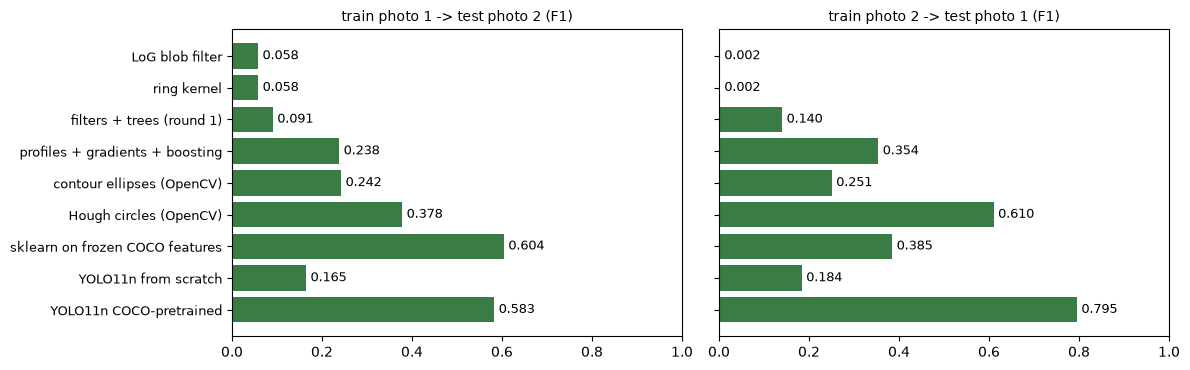

In [13]:
pd_ = saved('probe_dali.json')
ideas = [('LoG blob filter', cv['dali_1to2']['log']['target']['f1'], cv['dali_2to1']['log']['target']['f1']),
         ('ring kernel', cv['dali_1to2']['ring']['target']['f1'], cv['dali_2to1']['ring']['target']['f1']),
         ('filters + trees (round 1)', r1[(1, 'structural_gradient_stability')], r1[(2, 'structural_gradient_stability')]),
         ('profiles + gradients + boosting', prof[(1, 'profile_hog')], prof[(2, 'profile_hog')]),
         ('contour ellipses (OpenCV)', cv['dali_1to2']['ellipse']['target']['f1'], cv['dali_2to1']['ellipse']['target']['f1']),
         ('Hough circles (OpenCV)', cv['dali_1to2']['hough']['target']['f1'], cv['dali_2to1']['hough']['target']['f1']),
         ('sklearn on frozen COCO features', pd_['dali_1to2']['target']['f1'], pd_['dali_2to1']['target']['f1']),
         ('YOLO11n from scratch', ds['scratch_from1']['f1'], ds['scratch_from2']['f1']),
         ('YOLO11n COCO-pretrained', ds['pretrained_from1']['f1'], ds['pretrained_from2']['f1'])]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
plots.bars(ax[0], [i[0] for i in ideas], [i[1] for i in ideas], 'train photo 1 -> test photo 2 (F1)')
plots.bars(ax[1], [i[0] for i in ideas], [i[2] for i in ideas], 'train photo 2 -> test photo 1 (F1)')
plt.tight_layout(); plt.show()

Hough circles were the best thing with no learning (0.38/0.61), probably because they look for round edges instead of a brightness pattern. Still way below the pretrained detector. Mask R-CNN / Segment Anything I didn't run: they draw outlines, and counting only needs one point per barnacle.

## 7. Idea 4: show the model a little bit of the new photo i.e. adaptation mechanism (based on hypothesis that barnacles little variance amongst barnacles together meaning in one image but great variance across images due to lighting and environmental conditions)

This is the part I came up with after seeing the transfer results. Training on pieces of both photos did great; training on one and testing on the other didn't. So exposure to the photo's own conditions matters. But asking someone to label the whole photo defeats the point of automating it. So: label a small patch of the new photo and fine-tune on that. Tested by revealing mask labels only inside the patches (no real person). **[saved]**

In [14]:
hy = {r['tag']: r for r in saved('detector_hybrid.json')}
strip = {r['tag']: r['evaluations'][1]['f1'] for r in saved('detector_summary.json')}   # evaluations[1] = other photo's test strip
rows = []
for tag, base, name in [('pretrained_adapt_to1', 'pretrained_from2', 'pretrained, new photo = 1'), ('pretrained_adapt_to2', 'pretrained_from1', 'pretrained, new photo = 2'),
                        ('scratch_adapt_to1', 'scratch_from2', 'scratch, new photo = 1'), ('scratch_adapt_to2', 'scratch_from1', 'scratch, new photo = 2')]:
    r = hy[tag]
    rows.append({'model': name, 'labels in patch': r['annotation_labels'], 'before': strip[base],
                 'only re-pick threshold': r['threshold_only']['f1'], 'fine-tuned on patch': r['adapted']['f1']})
display(pd.DataFrame(rows).round(3))

,model,labels in patch,before,only re-pick threshold,fine-tuned on patch
0,"pretrained, new photo = 1",193,0.796,0.871,0.905
1,"pretrained, new photo = 2",61,0.573,0.564,0.751
2,"scratch, new photo = 1",193,0.133,0.435,0.787
3,"scratch, new photo = 2",61,0.198,0.200,0.471


Big jumps (scored on the new photo's test strip, which the patches don't touch). But 12.5% of the photo is still 61–193 labels. Smaller version: label 1–2 small squares (~27 labels each on photo 1, ~7 on photo 2), only re-pick the threshold, no retraining. **[saved]** (This run tiled the whole frame, so its 'before' is 0.807 instead of 0.796 above.)

In [15]:
ab = saved('adapt_budget.json')
rows = []
for tag, name in [('pretrained_from2', 'new photo = 1'), ('pretrained_from1', 'new photo = 2')]:
    for cells in ('1', '2'):
        s = ab[tag]['summary'][cells]
        rows.append({'new photo': name, 'squares labelled': cells, 'labels (avg)': s['labelled_objects']['mean'],
                     'F1 before': s['none']['f1_mean'], 'F1 after (avg of 20 tries)': s['threshold']['f1_mean'],
                     'count error before %': s['none']['abs_count_error_pct_mean'], 'count error after %': s['threshold']['abs_count_error_pct_mean']})
display(pd.DataFrame(rows).round(3))

,new photo,squares labelled,labels (avg),F1 before,F1 after (avg of 20 tries),count error before %,count error after %
0,new photo = 1,1,27.35,0.807,0.874,29.283,8.489
1,new photo = 1,2,52.55,0.807,0.877,29.283,8.692
2,new photo = 2,1,6.55,0.573,0.555,7.059,24.529
3,new photo = 2,2,12.25,0.573,0.522,7.059,37.118


Works on photo 1 (the model was just too cautious there, so moving the threshold fixes it). Makes photo 2 worse (F1 down, count error up from 7% to 25–37%): that model ranks barnacles wrong, and moving the threshold can't fix that. So a little labelling helps sometimes, not always. Nobody was timed doing this. So, I don't have clear judgement on how much time this saves as compared to annotating a full photo.

## 8. Outside photos (Roboflow)

Outside data is fine if it actually matches the barnacles I'm counting. I found a Roboflow set: 561 close-up photos from Welsh shores, labelled as whole shells (not openings). Totally different camera distance, so each photo gets shrunk by one factor picked on separate photos. Split by survey so test photos come from different surveys than the tuning ones. **[saved]**

In [16]:
mx = saved('main_external.json'); fs = mx['fixed_scale']
prb = saved('probe.json')['rf']['test']; one = saved('detectors_external.json')['pretrained_from2']['fixed_scale']['calibrated']
display(pd.DataFrame([
    dict(model='main model, shrunk x0.7, its own threshold', F1=fs['own_threshold']['f1'], **{'count error %': fs['own_threshold']['weighted_abs_pct']}),
    dict(model='main model at original size (just to compare)', F1=mx['test_f1_by_factor_DIAGNOSTIC']['1.0'], **{'count error %': np.nan}),
    dict(model='classifier on COCO features, trained on 100 of these photos', F1=prb['f1'], **{'count error %': prb['weighted_abs_pct']}),
    dict(model='COCO model trained on photo 2 only, shrunk x0.5, threshold re-picked on Roboflow photos', F1=one['f1'], **{'count error %': one['weighted_abs_pct']}),
]).round(3))
print(f"{mx['n_test']} test photos from {mx['n_test_groups']} survey groups; 95% range for the main model: {np.round(fs['own_threshold']['f1_group_ci95'], 3)}")
print(f"main model total vs true total: {fs['own_threshold']['signed_total_pct']:+.0f}%")

,model,F1,count error %
0,"main model, shrunk x0.7, its own threshold",0.757,23.617
1,main model at original size (just to compare),0.712,NaN
2,"classifier on COCO features, trained on 100 of...",0.751,20.035
3,"COCO model trained on photo 2 only, shrunk x0....",0.625,36.825


97 test photos from 9 survey groups; 95% range for the main model: [0.598 0.831]
main model total vs true total: -14%


The main model holds up OK on totally different photos once the size is matched (0.757), about the same as a classifier trained on those photos. It undercounts there, though (14% too few overall).

An earlier ChatGPT run tested the same model on its own split of these photos (0.733 on 112 test photos) and trained a model on the outside photos plus the left strips of my two photos: 0.804 on its outside test photos, but about 0.70/0.68 on my photos' test strips (run over each full photo, not strip-only like the 0.941). So more outside data helped on outside photos and hurt on mine. Those numbers are copied from ChatGPT's report into `results/recorded/chatgpt_round5_reported.json`, not re-run here.

## 9. The real test: a new photo I counted myself

`unseen_img1` has no labels, so I counted part of it by hand. `unseen_img2` turned out to be a zoomed-in crop of `unseen_img1` (about 10% of the frame). I marked **135** barnacles on it (centre-inside rule, no empty shells). First find exactly where the crop sits. **[runs]**

In [17]:
marks = mk.read_marks('data/unseen_img2_marked_135.png', 'data/unseen_img2.png')
A, fit = mk.find_crop('data/unseen_img2.png', 'data/unseen_img1.png')
print(len(marks), 'hand marks')
print({k: round(v, 4) for k, v in fit.items()})

135 hand marks
{'matches': 290, 'inliers': 268, 'median_residual_px': 0.0649, 'scale': 0.6275}


Now run the normal pipeline on the whole `unseen_img1` (straighten frame → tiles → model → threshold 0.37), and only score the dots inside my area. **[runs]**

whole frame: 1143 dots
my area: 130 dots vs 135 barnacles -> 128 found, 2 extra, 7 missed, F1 0.966 (strict rule 0.928)


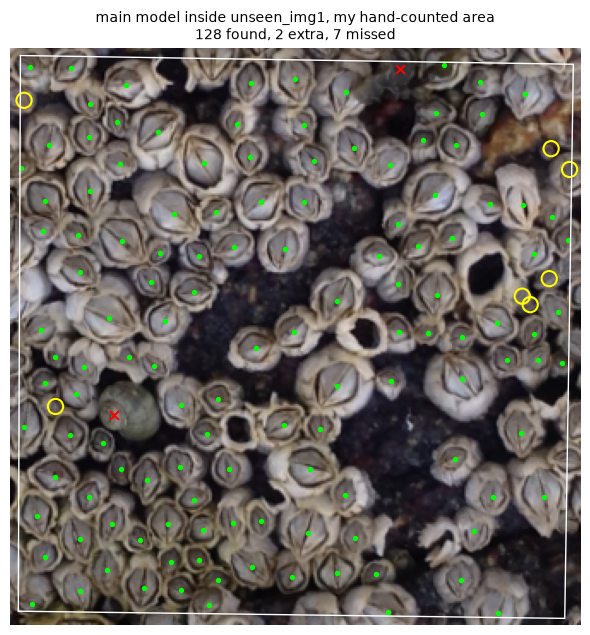

In [18]:
rgb_u, Mu = bc.rectify(bc.read_rgb('data/unseen_img1.png'), frames['unseen_img1.png'])
d = det.dots(rgb_u); d = d[d[:, 3] >= cfg['threshold']]
area = mk.crop_to_frame([[0, 0], [499, 0], [499, 499], [0, 499]], A, Mu)   # my area, in frame pixels
marks_f = mk.crop_to_frame(marks, A, Mu)
s = mk.area_scale(area)
di = d[mk.inside(area, d[:, :2])]
ref_same = np.column_stack([marks_f, mk.same_barnacle_tolerance(marks) * s])   # dot on the same barnacle as my mark
ref_strict = np.column_stack([marks_f, np.full(len(marks), 8 * s)])            # dot within ~5px of my mark's centre
same, strict = bc.metrics(di, ref_same, 1.0), bc.metrics(di, ref_strict, 1.0)
print(f'whole frame: {len(d)} dots')
print(f"my area: {len(di)} dots vs {len(marks)} barnacles -> {same['tp']} found, {same['fp']} extra, {same['fn']} missed, F1 {same['f1']:.3f} (strict rule {strict['f1']:.3f})")

x0, y0 = np.floor(area.min(0)).astype(int) - 4; x1, y1 = np.ceil(area.max(0)).astype(int) + 4
fig, ax = plt.subplots(figsize=(7.5, 7.5))
plots.show_match(ax, rgb_u[y0:y1, x0:x1], di - [x0, y0, 0, 0], ref_same - [x0, y0, 0], 'main model inside unseen_img1, my hand-counted area', tolerance=1.0)
ax.plot(*np.vstack([area, area[:1]]).T - np.array([[x0], [y0]]), 'w-', lw=1)
plt.show()

128 of my 135 found, 2 extra (a snail and a dark spot at the top edge), 7 missed (indicated in the yellow rings). 2 of the misses (indicated by the red xs) are right on the edge of my area (the dot probably landed just outside), 3 are tiny ones squeezed next to a big empty shell. With the strict rule (dot within about 5px of the centre of my mark) it's 0.928.

Honest note: this is my second count of this area. My first one (138 marks, left out every barnacle cut by the edge) gave 0.948, and only 0.754 with the strict rule. I re-marked it with the centre-inside rule after seeing those results, putting the marks closer to each opening's centre. Both are in `data/`, and the first one's results are in `experiments/Barnacle_Brief_Ideas_Study/results/v1_marks_138/`.

How every saved model does on the same area, same pipeline **[saved]**:

In [19]:
names = {'main_model': 'MAIN MODEL (pretrained, both photos)', 'pretrained_from1': 'pretrained, photo 1 only', 'pretrained_from2': 'pretrained, photo 2 only',
         'pretrained_adapt_to1': 'pretrained, photo 2 + patch of 1', 'pretrained_adapt_to2': 'pretrained, photo 1 + patch of 2',
         'scratch_mixed_styles': 'scratch, both photos', 'scratch_from1': 'scratch, photo 1 only', 'scratch_from2': 'scratch, photo 2 only',
         'scratch_adapt_to1': 'scratch, photo 2 + patch of 1', 'scratch_adapt_to2': 'scratch, photo 1 + patch of 2',
         'probe_roboflow': 'COCO features + classifier, Roboflow only', 'hough_tuned_on_photo1': 'Hough circles (photo 1 settings)',
         'hough_tuned_on_photo2': 'Hough circles (photo 2 settings)'}
pp = saved('unseen2_in_pipeline.json')['models']
t = pd.DataFrame([{'model': names[k], 'dots in area': v['region_count'], 'F1': v['same_barnacle']['f1'], 'F1 strict': v['strict']['f1'],
                   'whole-frame count': v['whole_quadrat_count']} for k, v in pp.items()]).sort_values('F1', ascending=False)
display(t.round(3))

,model,dots in area,F1,F1 strict,whole-frame count
1,"pretrained, photo 1 only",136,0.974,0.945,1243
0,"MAIN MODEL (pretrained, both photos)",130,0.966,0.928,1143
4,"pretrained, photo 1 + patch of 2",131,0.962,0.925,1162
5,"scratch, both photos",125,0.954,0.938,1096
9,"scratch, photo 1 + patch of 2",123,0.946,0.922,1076
3,"pretrained, photo 2 + patch of 1",126,0.943,0.912,1110
2,"pretrained, photo 2 only",115,0.912,0.888,944
8,"scratch, photo 2 + patch of 1",129,0.879,0.864,1122
6,"scratch, photo 1 only",160,0.861,0.841,1470
10,"COCO features + classifier, Roboflow only",101,0.771,0.661,859


The top pretrained models are within a few barnacles of each other here, which doesn't mean much on one area of one photo. The main model's whole-frame count is 1,143. My area was 4% low (130 vs 135), but that area isn't a random sample, so I can't scale that up into a corrected total.

## 10. Making the count trustworthy: random audit

F1 doesn't tell a scientist how far off the total is. So: a person fully counts 16 random tiles (out of 64), we compare with the model on those tiles, correct the total, and get a 95% interval. Simulated here with the photo-2-only model on photo 1 (a photo it never saw), with the mask labels pretending to be the person. **[runs]**

In [20]:
det2 = bc.Detector('models/photo2_only_pretrained.pt')
thr2 = json.loads(Path('models/photo2_only_pretrained.json').read_text())['threshold']
d2 = det2.dots(photos[1]['rgb']); d2 = d2[d2[:, 3] >= thr2]
mc, rc = audit.tile_counts(d2[:, :2]), audit.tile_counts(photos[1]['ref'][:, :2])
print(f'model count {mc.sum()} vs true {rc.sum()} ({100 * (mc.sum() - rc.sum()) / rc.sum():+.0f}%)')
with_model = audit.simulate_audits(mc, rc, n=16, repeats=5000, seed=23)
by_hand = audit.simulate_audits(mc, rc, n=16, repeats=5000, seed=23, beta=0.)
print(f"model + 16 random tiles: +/-{with_model['mean_half_width_pct']:.1f}%, interval contains the truth {100 * with_model['coverage95']:.0f}% of the time")
print(f"same 16 tiles counted by hand, no model: +/-{by_hand['mean_half_width_pct']:.1f}%")

model count 1190 vs true 1659 (-28%)
model + 16 random tiles: +/-9.0%, interval contains the truth 94% of the time
same 16 tiles counted by hand, no model: +/-12.8%


The model alone was 28% low, the audit pulls it to ±9%. But 16 tiles is a quarter of the frame (~415 barnacles on this photo), not a quick check. Saved runs: labelling 2 small squares first gets it to ±6% on photo 1. On sparse photo 2 it's ±17% (±18% with the 2 squares). And the "95%" interval isn't guaranteed: in ChatGPT's test on the outside photos it only held the true count 80% of the time with 8 tiles and 89% with 16 (`results/recorded/chatgpt_round5_reported.json`). Again, no real person was timed.

## 11. The human steps (keep them separate)

| step              | person does                          | what changes               | in this repo                                             |
|---                |---                                   |---                         |---                                                       |
| automatic         | marks 4 frame corners                | nothing                    | `scripts/predict.py`                                     |
| re-pick threshold | fully labels 1–2 small squares       | threshold only             | simulation only                                          |
| fine-tune         | labels a 12.5% patch                 | model weights              | earlier training runs (need PyTorch)                     |
| review            | removes wrong dots, adds missed ones | the count                  | review pages in `experiments/` (built with other models) |
| random audit      | fully counts 16 random tiles         | corrected total ± interval | `barnacle_counter/audit.py`, simulation only             |

## 12. What didn't work
- strict ring/slit rules and fixed kernels (≤ 0.14 on a new photo): This led me to come up with a hypothesis around the idea that barnacles in an area perhaps share similar genetics causing their elliptical shapes and size to be similar. However, a quick google search would prove me wrong the only similarity would likely be background, coloration, and buildup since barnacles in the same area are exposed to similar conditions.
- richer hand features alone (0.24/0.35)
- Hough circles as a second opinion for YOLO (no gain)
- picking the threshold from the photo's own confidence scores: helped 2 of 4 models on my photos, hurt the other 2, and failed on the outside photos (0.469)
- guessing the barnacle size from texture (no correlation with real size; `experiments/Barnacle_Brief_Ideas_Study/results/scale_estimators.json`)
- averaging two models on the outside photos (worse than the better one alone)

## 13. Limits
- only 2 labelled photos, and the main model trained on both. Only one area (~10%) of one new photo has a hand count.
- the "same barnacle" scoring rule was picked after looking at results. The strict rule set beforehand is shown next to it every time.
- I re-did my hand count after seeing the first results (see section 9).
- the human steps are simulations with the mask labels. Nothing was timed.
- the model doesn't distinguish or know live vs dead. Also there is slight counting ambiguity with barnacles on the edges of the photo. 
- outside photos were grouped by survey from file names. Rough, so those scores may be a bit optimistic.

## 14. What I learned

The big thing I learned was realizing how difficult the problem actually was. I was expecting higher results on my first trial, but I realized quickly that the lack of data as well as my poor parameters did not create conditions for a successful model: especially since I wanted to make the model fully automated as well. Because of that, my approach kept changing after each failure. To provide a timeline: I started by trying to describe barnacles by their prominent features after the filters (rings, slits, lighting) and turn that into the parameters. That was ineffective on the real photos, so I moved to letting a model learn the features itself, which worked way better. However, understanding that the higher performance has some bias due to the training data being so similar to the testing data, I wanted to gauge a more realistic result. Thus, I decided to do separates tests or models trained on each training set. On a photo it hadn't seen, it dropped a lot. With only two photos, each with its own local quirks, that's expected. This especially the case with the different backgrounds buildup on the barnacles all eventually distorting the clarity of photos the model took in. For example, the 2nd annotated photo has a greater degree of buildup on barnacles causing the color difference between rings to be far less prominent. From this, I took the hypothesis that to effectively count barnacles it could be worthwhile to expose the model to the conditions of the barnacles as I'd assume said conditions would carry-on for the image as a whole. Seeing that training on pieces of both photos worked so well is what gave me the adaptation idea: since nobody's going to annotate a whole photo they want automated, label a small piece of it and fine-tune on that.

Also: having a reason behind each decision mattered more than the score, and F1 isn't the count, so if a scientist needs a number they can trust, the random audit matters more than squeezing out more F1.

The most exciting part about this whole process was seeing the gradual climb of the model performance. It was especially rewarding because of how poorly it began with a model that hardly distinguish a rock cavity from a barnacle. Thus, when I first attain the 0.941 F1 value I was ecstatic because that was so promising.

## AI use
I brainstormed the process and each change of direction. AI tools helped me to write a sizeable portion of the code since I wanted to test many different methods so writing and organizing each individually would have been a nightmare. I reviewed the results and refined it for each output, partly by telling them what to change and partly by altering the code by-hand: I hand-edited the code for the gradient and other visual-feature tests as I wanted to set specific parameters. The AI ran the other segments of the code and all the model training in its own workspace (ChatGPT for the early rounds and the main model, Claude for the later rounds and this repo). Since I also wanted to test my models on novel images, I did the hand annotations for those images, clarified the counting rules with Paul, and obtained outside from RoboFlow since I wanted to expand the testing. Details are in the README.